# Exploring How Skills Trend Throughout the Year

## Methodology

1. Aggregate skill counts by month.
2. Analyse the data baed on percentage of total jobs.
3. Plot the monthly skill demands.

In [201]:
#Import libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text

#Load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

#Focus on UK Data Analyst jobs
df_uk = df[(df['job_country'] == 'United Kingdom') & (df['job_title_short'] == 'Data Analyst')].copy()

## Data Preparation

In [ ]:
#Create column for month of each job posting
df_uk['job_posted_month_no'] = df_uk['job_posted_date'].dt.month
df_uk.head(3)

In [ ]:
#Explode the skills for each role
df_uk_explode = df_uk.explode('job_skills')
df_uk_explode.head(3)

In [ ]:
#Pivot the data to get a count of skills for each month
df_uk_pivot = df_uk_explode.pivot_table(index = 'job_posted_month_no',
                                        columns='job_skills',
                                        aggfunc='size',
                                        fill_value=0)

In [ ]:
# Sort skills by count
df_uk_pivot.loc['Total'] = df_uk_pivot.sum()
df_uk_pivot = df_uk_pivot[df_uk_pivot.loc['Total'].sort_values(ascending=False).index]
df_uk_pivot = df_uk_pivot.drop('Total')
df_uk_pivot.head(3)

In [ ]:
#Find number of job posts in each month
df_totals = df_uk.groupby('job_posted_month_no').size()
df_totals.head(3)

In [135]:
#Divide the skills by the number of job posts in each month
df_perc = df_uk_pivot.div(df_totals/100,axis='index')
df_perc.head(3)

job_skills,sql,excel,power bi,python,tableau,r,sas,azure,go,powerpoint,...,kotlin,laravel,flutter,redis,selenium,sqlite,ubuntu,svelte,watson,workfront
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,41.376960,39.604635,25.289707,18.132243,13.905930,9.611452,8.588957,4.976142,3.680982,5.316973,...,0.0,0.0,0.068166,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
2,42.816365,45.575642,27.307326,17.031399,16.270219,8.658421,8.753568,6.184586,4.376784,4.281637,...,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.095147
3,42.275281,41.994382,24.438202,16.853933,16.432584,9.410112,7.303371,5.337079,5.898876,6.039326,...,0.0,0.0,0.000000,0.0,0.0,0.140449,0.0,0.0,0.0,0.000000


In [136]:
# Change months from numbers to short names
df_perc = df_perc.reset_index()
df_perc['job_month'] = df_perc['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_perc = df_perc.set_index('job_month')
df_perc = df_perc.drop(columns = 'job_posted_month_no')

df_perc

job_skills,sql,excel,power bi,python,tableau,r,sas,azure,go,powerpoint,...,kotlin,laravel,flutter,redis,selenium,sqlite,ubuntu,svelte,watson,workfront
job_month,,,,,,,,,,,,,,,,,,,,,
Jan,41.376960,39.604635,25.289707,18.132243,13.905930,9.611452,8.588957,4.976142,3.680982,5.316973,...,0.000000,0.000000,0.068166,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Feb,42.816365,45.575642,27.307326,17.031399,16.270219,8.658421,8.753568,6.184586,4.376784,4.281637,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.095147
Mar,42.275281,41.994382,24.438202,16.853933,16.432584,9.410112,7.303371,5.337079,5.898876,6.039326,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.140449,0.000000,0.000000,0.000000,0.000000
Apr,40.998217,40.463458,28.520499,16.042781,13.368984,8.377897,6.773619,5.704100,4.812834,6.951872,...,0.000000,0.000000,0.000000,0.178253,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
May,42.019544,40.553746,26.221498,15.635179,12.377850,8.631922,6.514658,5.863192,4.723127,4.397394,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Jun,38.315217,40.353261,24.592391,16.032609,12.907609,7.065217,4.891304,4.891304,5.027174,4.619565,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Jul,44.618834,44.170404,33.295964,22.645740,11.883408,10.874439,8.744395,12.443946,5.044843,9.417040,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Aug,42.622951,42.950820,28.032787,17.868852,13.770492,8.360656,5.901639,6.885246,6.393443,4.590164,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Sep,44.784173,40.557554,28.597122,22.931655,18.525180,12.949640,7.374101,6.294964,5.485612,4.316547,...,0.089928,0.089928,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.089928,0.000000


In [ ]:
df_plot.iloc[-1,0]


np.float64(37.92134831460674)

## Plotting Data

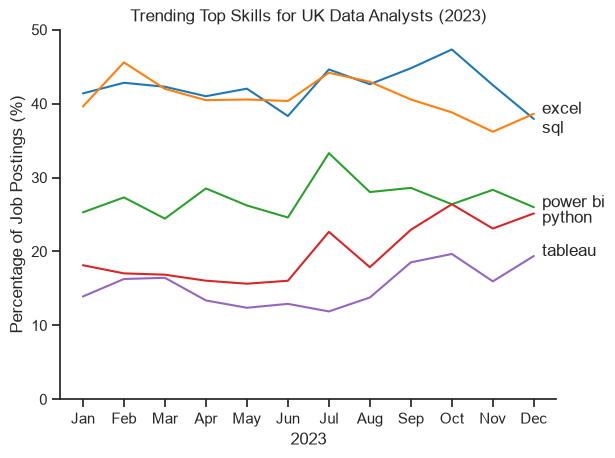

In [ ]:
#Subset data for the top 5 skills in each month
df_plot = df_perc.iloc[:,0:5]

#Use Seaborn to create a lineplot
sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.set_theme(style='ticks')
sns.despine()

#Format the axes and legend
plt.title('Trending Top Skills for UK Data Analysts (2023)')
plt.xlabel('2023')
plt.ylabel('Percentage of Job Postings (%)')
plt.ylim(0,50)
plt.legend().set_visible(False)

#Format the data labels
for i in range(5):
    #Correct for overlap of sql and python labels
    if df_plot.columns[i] in ["sql", "python"]:
        plt.text(x=11.2, y=df_plot.iloc[-1, i]*0.95, s=df_plot.columns[i])
    else:
        plt.text(x=11.2, y=df_plot.iloc[-1, i]*1, s=df_plot.columns[i])

plt.savefig('Figures/Skills_Trend.png')
plt.show()
